In [68]:
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

In [69]:
df = pd.read_csv('../csv/club_games.csv')
print(df.dtypes)
df

game_id                    int64
club_id                    int64
own_goals                  int64
own_position             float64
own_manager_name          object
opponent_id                int64
opponent_goals             int64
opponent_position        float64
opponent_manager_name     object
hosting                   object
is_win                     int64
dtype: object


,game_id,club_id,own_goals,own_position,own_manager_name,opponent_id,opponent_goals,opponent_position,opponent_manager_name,hosting,is_win
0,2221751,431,1,NaN,Lutz Göttling,60,2,NaN,Christian Streich,Home,0
1,2221755,83,3,NaN,Ralph Hasenhüttl,4795,0,NaN,Tomas Oral,Home,1
2,2222597,3725,2,2.0,Stanislav Cherchesov,232,1,5.0,Unai Emery,Home,1
3,2222627,2696,0,11.0,Andrey Kobelev,4128,2,10.0,Rustem Khuzin,Home,0
4,2222658,2410,0,2.0,Leonid Slutski,121,2,13.0,Dan Petrescu,Home,0
...,...,...,...,...,...,...,...,...,...,...,...
130427,4126931,20923,2,NaN,Sergey Perednya,12065,1,NaN,Aleksandr Gorbachev,Away,1
130428,4148237,920,0,NaN,Ruaidhri Higgins,10481,1,NaN,Milic Curcic,Away,0
130429,4171268,681,2,NaN,Imanol Alguacil,409,0,NaN,Gerhard Struber,Away,1
130430,4148252,144,3,NaN,Sergej Jakirovic,10532,1,NaN,Dan Brimsvík,Away,1


# Data Exploration
The dataset contains 11 columns and 130432 rows. The columns are:
- `game_id`: The unique identifier of the game
- `club_id`: The unique identifier of the club that played in home
- `own_goals`: The number of own goals scored by the home team
- `own_position`: The position of the home team in the league
- `own_manager_name`: The name of the manager of the home team
- `opponent_id`: The unique identifier of the club that played as visitor
- `opponent_goals`: The number of goals scored by the visitor team
- `opponent_position`: The position of the visitor team in the league
- `opponent_manager_name`: The name of the manager of the visitor team
- `hosting`: indicates if the home team is the hosting team or not
- `is_win`: indicates if the home team won the game or not
We are going also to change the data type of the columns `own_position` and `opponent_position` to integer.

## Data Cleaning

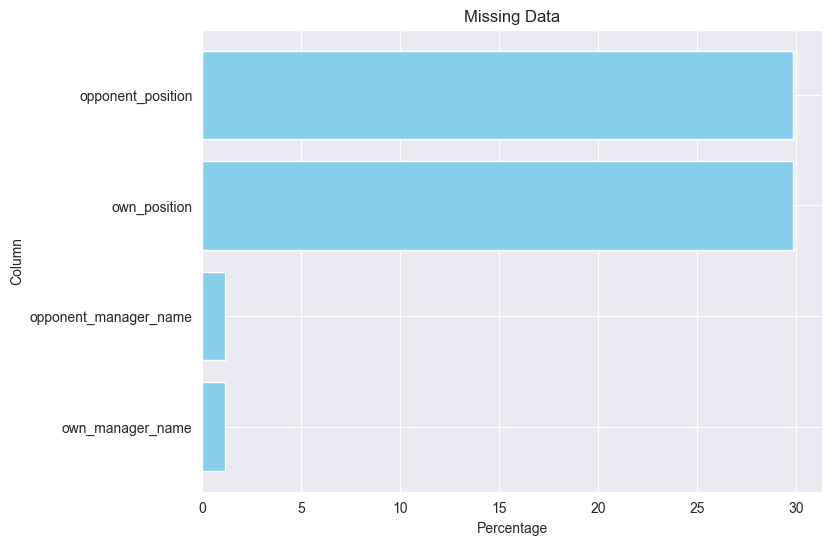

In [70]:
df['own_position'] = df['own_position'].astype('Int64')
df['opponent_position'] = df['opponent_position'].astype('Int64')

#check for duplicated rows
df.duplicated().sum()

#check for missing values
missing_values = df.isnull().mean() * 100
missing_values = missing_values[missing_values > 0].sort_values(ascending=True)  

# plt.figure -> Create a new figure with dimensions 8x6
plt.figure(figsize=(8, 6))
plt.barh(missing_values.index, missing_values.values, color='skyblue')  # Use barh for horizontal bars
plt.title('Missing Data')
plt.xlabel('Percentage')
plt.ylabel('Column')
plt.xticks(rotation=0)
plt.show()

## Visualization of the missing data
The dataset has no duplicated rows. There are missing values in the columns `opponent_position` , `own_position`, `opponent_manager_name` and `onw_manager_name`. We are going to modify the dataset only for the columns `opponent_manager_name` and `own_manager_name`.

In [71]:
df.loc[df['opponent_manager_name'].isnull(), 'opponent_manager_name'] = 'unknown'
df.loc[df['own_manager_name'].isnull(), 'own_manager_name'] = 'unknown'
df.query('opponent_manager_name == "unknown" or own_manager_name == "unknown"')

,game_id,club_id,own_goals,own_position,own_manager_name,opponent_id,opponent_goals,opponent_position,opponent_manager_name,hosting,is_win
265,2258371,17797,0,<NA>,unknown,317,1,<NA>,unknown,Home,0
325,2289248,3060,0,4,unknown,2079,0,14,unknown,Home,0
329,2289291,3060,0,4,unknown,6676,2,2,unknown,Home,0
599,2366500,20417,5,<NA>,unknown,22235,0,<NA>,unknown,Home,1
601,2366512,24391,0,<NA>,unknown,369,5,<NA>,unknown,Home,0
...,...,...,...,...,...,...,...,...,...,...,...
130057,4072488,36,3,3,unknown,7775,0,19,unknown,Away,1
130058,4072493,7775,0,19,unknown,589,3,12,unknown,Away,0
130095,4157243,5091,7,<NA>,unknown,77305,0,<NA>,unknown,Away,1
130193,4115648,5792,4,<NA>,unknown,13457,0,<NA>,unknown,Away,1


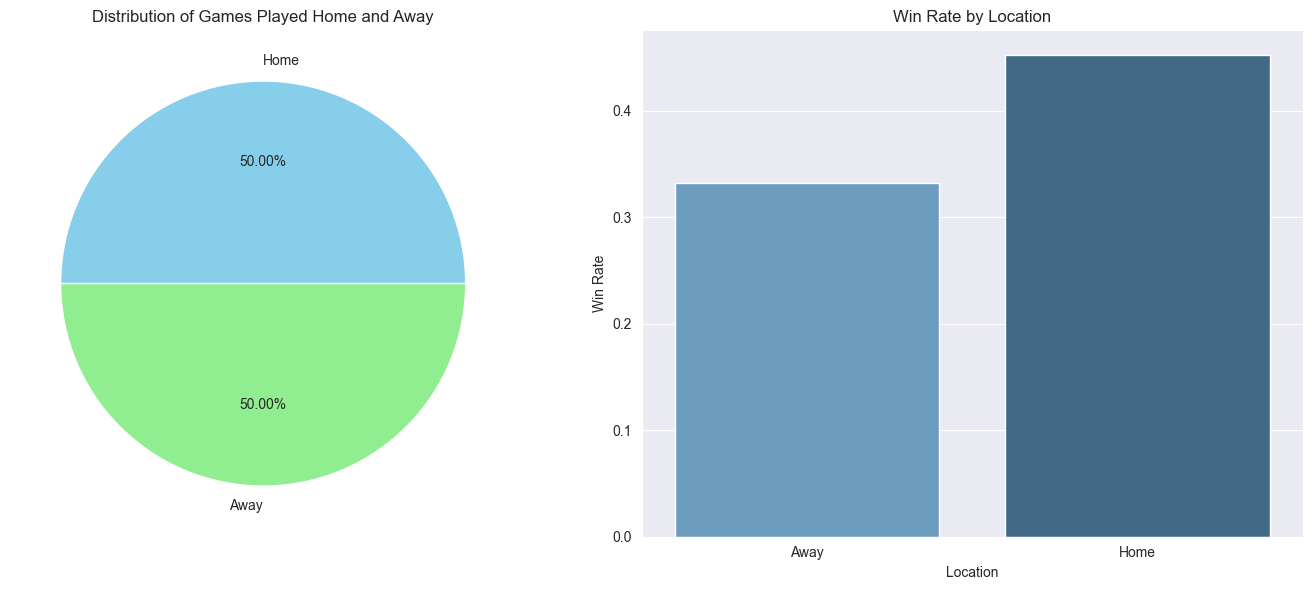

In [72]:
# Creating a figure with two subplots
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Plotting the number of games played home and away
games = df.groupby('hosting')
games_dim = games.size()

# Creating a pie chart
ax[0].pie(games_dim, autopct='%.2f%%', colors=['skyblue', 'lightgreen'], labels=['Home', 'Away'])
ax[0].set_title('Distribution of Games Played Home and Away')

# Calculating the win rate by location
win_rate = df.groupby('hosting')['is_win'].mean().reset_index()
win_rate.columns = ['Location', 'Win Rate']

# Bar plot for win rates with updated hue handling
sns.barplot(x='Location', y='Win Rate', data=win_rate, palette='Blues_d', hue='Location', ax=ax[1], legend=False)
ax[1].set_title('Win Rate by Location')
ax[1].set_ylabel('Win Rate')
ax[1].set_xlabel('Location')

# Adjust layout
plt.tight_layout()
plt.show()

## Distribution of games played home and away
The pie chart shows that the home team played 50.00% of the games at home and 50.00% of the games away, so we have a balanced dataset.
Furthermore, the bar chart shows the win rate by location. The win rate is higher for games played at home compared to games played away. This suggests that playing at home may provide a competitive advantage for the home team.

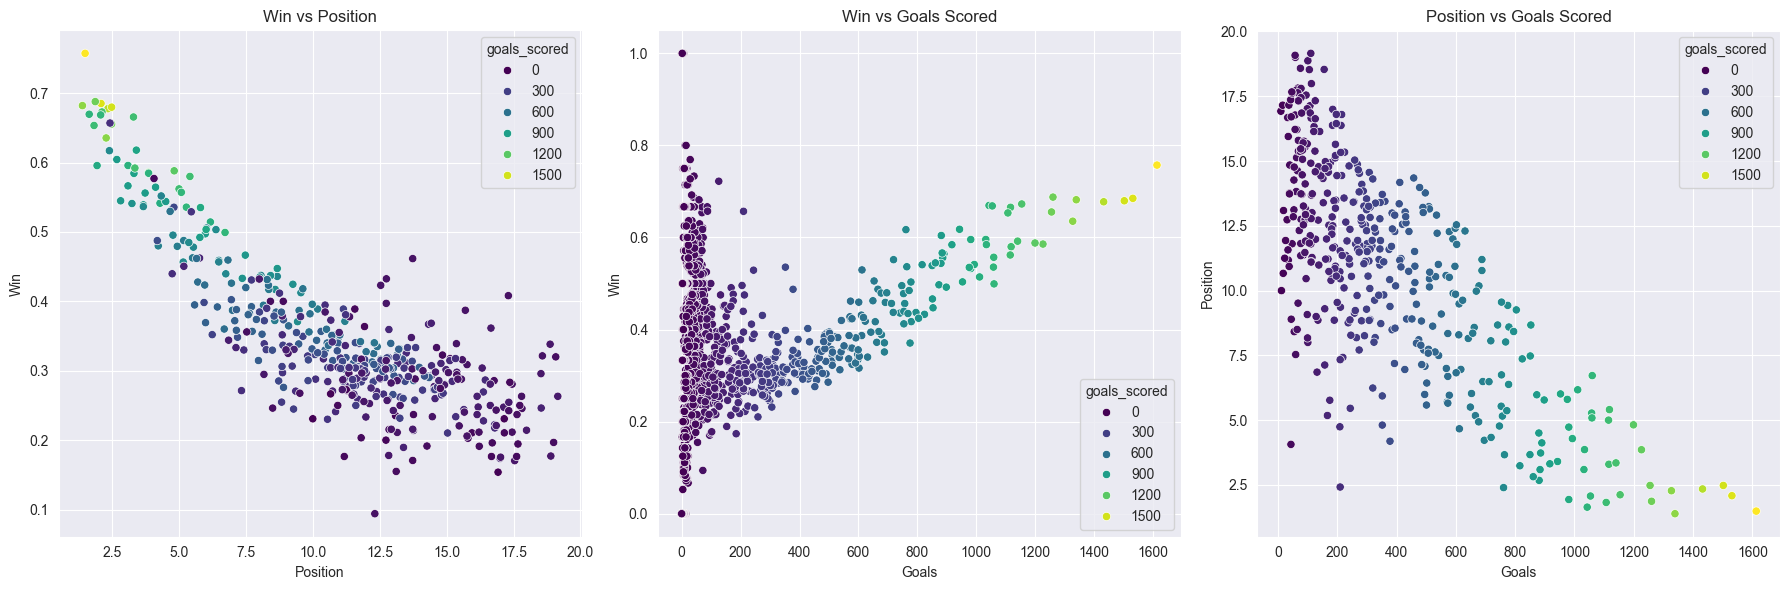

In [73]:
points = df.groupby('club_id').agg(
    is_win=('is_win', 'mean'),
    goals_scored=('own_goals', 'sum'),
    own_position=('own_position', 'mean'),
)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))

# Scatter plot position vs points
sns.scatterplot(x='own_position', y='is_win', data=points, hue='goals_scored', palette='viridis', ax=ax[0])
ax[0].set_title('Win vs Position')
ax[0].set_xlabel('Position')
ax[0].set_ylabel('Win')

# Scatter plot goals scored vs points
sns.scatterplot(x='goals_scored', y='is_win', data=points, hue='goals_scored', palette='viridis', ax=ax[1])
ax[1].set_title('Win vs Goals Scored')
ax[1].set_xlabel('Goals')
ax[1].set_ylabel('Win')

# Scatter plot goals scored vs position
sns.scatterplot(x='goals_scored', y='own_position', data=points, hue='goals_scored', palette='viridis', ax=ax[2])
ax[2].set_title('Position vs Goals Scored')
ax[2].set_xlabel('Goals')
ax[2].set_ylabel('Position')


plt.tight_layout()
plt.show()

## Visual Analysis of Team Performance Metrics

The visualizations provide insights into the relationships between team performance metrics such as wins, goals scored, and league position.

### 1. Points vs Position
The scatter plot illustrates the relationship between a team's league position and its win percentage. Each point represents a club, with the color indicating the total goals scored. 

- **X-axis**: League Position (lower values indicate a better position)
- **Y-axis**: Win Percentage (mean of `is_win`, where 1 indicates a win)
- We can observe that teams with higher league positions tend to have higher win percentages.

### 2. Points vs Goals Scored
This scatter plot shows the relationship between the total goals scored by a team and its win percentage. 

- **X-axis**: Total Goals Scored
- **Y-axis**: Win Percentage (mean of `is_win`)
- The visualization suggests that teams with higher goals scored tend to have higher win percentages.

### 3. Position vs Goals Scored
In this plot, we examine the relationship between the total goals scored and the league position of the teams. 

- **X-axis**: Total Goals Scored
- **Y-axis**: League Position
- The visualization indicates that teams with higher goals scored tend to have better league positions.

These visualizations help us understand how a team's performance metrics are interrelated and provide insights into the factors influencing success in the league.


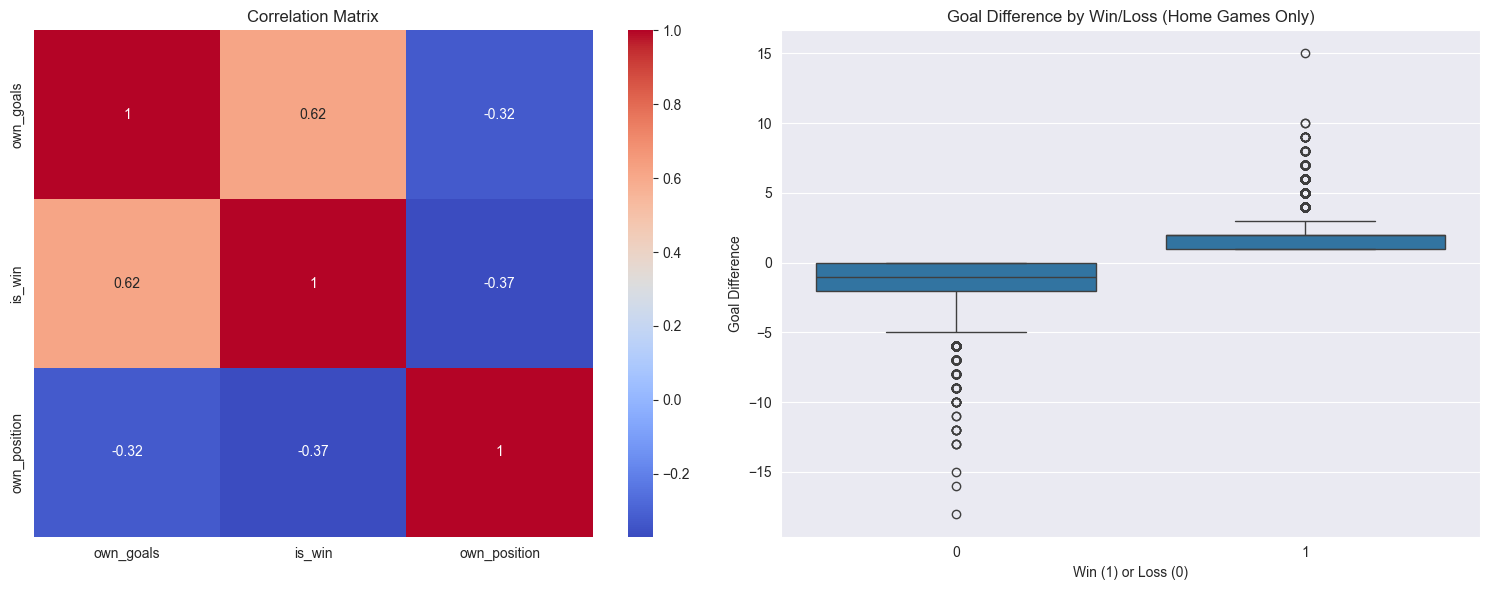

In [74]:
correlation_matrix = df[['own_goals', 'is_win', 'own_position']].corr()

# Create subplots
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Plot the correlation matrix heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', ax=ax[0])
ax[0].set_title('Correlation Matrix')

home_games = df[df['hosting'] == 'Home'].copy()
home_games['goal_difference'] = home_games['own_goals'] - home_games['opponent_goals']

# Calculate goal difference
df['goal_difference'] = df['own_goals'] - df['opponent_goals']

# Plot the boxplot for goal difference by win/loss for home games only
sns.boxplot(x='is_win', y='goal_difference', data=home_games, ax=ax[1])
ax[1].set_title('Goal Difference by Win/Loss (Home Games Only)')
ax[1].set_xlabel('Win (1) or Loss (0)')
ax[1].set_ylabel('Goal Difference')

df.drop('goal_difference', axis=1, inplace=True)
# Adjust layout
plt.tight_layout()
plt.show()

## Correlation Matrix and Goal Difference Analysis
The correlation matrix provides insights into the relationships between different variables in the dataset. The heatmap visualizes the correlation coefficients between the variables `own_goals`, `is_win`, and `own_position`.
We can observe that:
- There is a positive correlation between `own_goals` and `is_win`, indicating that the home team's goals scored are associated with winning games.
- The `own_position` variable has a negative correlation with `is_win`, meaning that as the number of goals scored increases, the team's position in the league generally improves. This could indicate that offensive performance is a key factor in a team's success.
- The `own_goals` and `own_position` variables have a weak negative correlation, it has same meaning as the correlation between `own_position` and `is_win`.

## Goal Difference by Win/Loss for Home Games Only

This boxplot visualizes the goal difference based on whether the home team won or lost. The data is filtered to include only home games. We can observe that the goal difference is generally higher for wins compared to losses.

The boxplot reveals that:
- When the home team wins:
    - the goal difference is predominantly positive,
    - there are several outliers with very high positive goal differences, suggesting that some matches were won by a wide margin.
- When the home team loses:
    - the goal difference is generally negative, that means that the opponent team scored more goals than the home team,
    - there are a few outliers on the negative side, indicating instances where the home team suffered particularly heavy defeats.

# Most Winning Manager

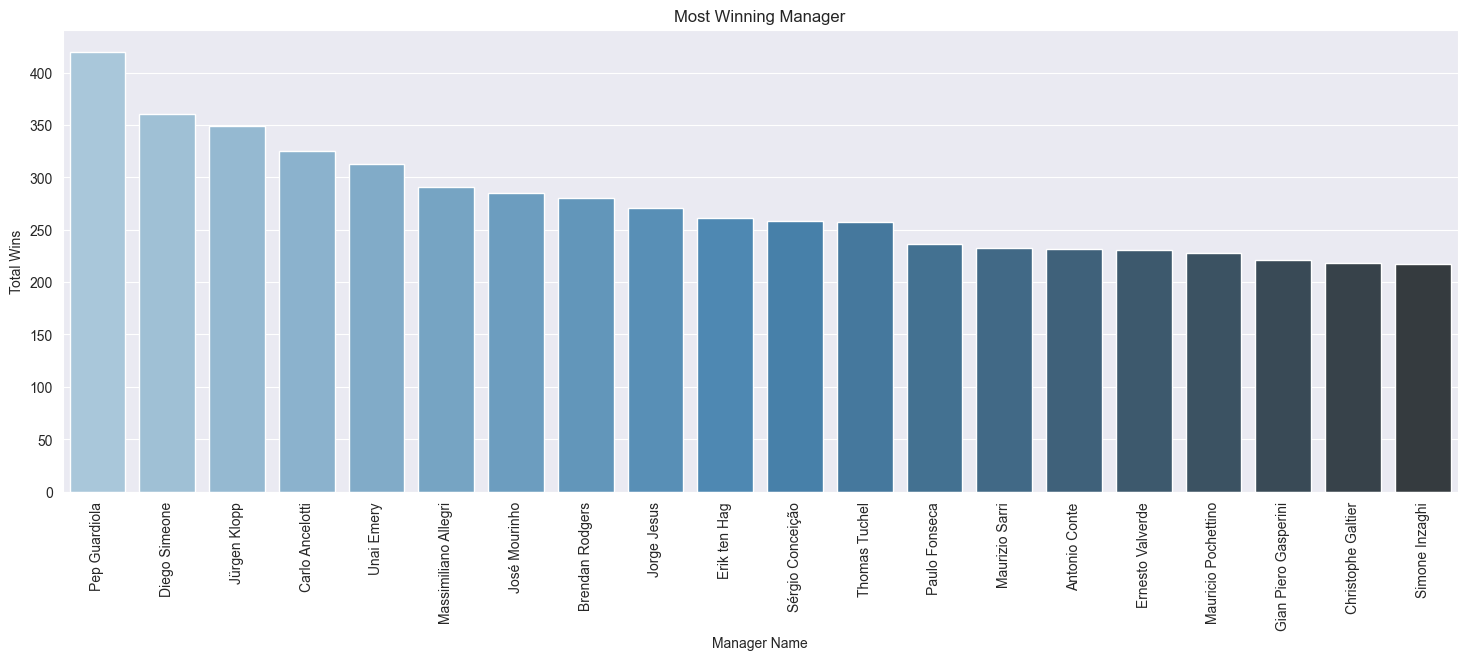

In [75]:
df_filtered = df[df['own_manager_name'] != 'unknown']

manager_wins = df_filtered.groupby('own_manager_name').agg(
    total_wins=('is_win', 'sum'),
    games_played=('game_id', 'count')  # To calculate the win rate
)

#Calculatin win rate
manager_wins['win_rate'] = manager_wins['total_wins'] / manager_wins['games_played']

# Sort managers by win rate or total wins
top_manager = manager_wins.sort_values(by='total_wins', ascending=False).head(20)

#Plot the most successful manager
plt.figure(figsize=(18, 6))
sns.barplot(x=top_manager.index, y=top_manager['total_wins'], hue=top_manager.index, palette='Blues_d', legend=False)
plt.title(f"Most Winning Manager")
plt.xlabel('Manager Name')
plt.ylabel('Total Wins')
plt.xticks(rotation=90)
plt.show()

### Most Winning Manager

The bar chart visualizes the top managers based on the total number of wins. The data is grouped by manager names, and the number of wins for each manager is calculated. 

Managers with an "unknown" name were excluded to focus on identified managers. The bar chart allows us to identify the most successful managers in terms of wins, with **Pep Guardiola** leading the chart, followed by **Diego Simeone** and **Jürgen Klopp**.

- The data suggests that these managers consistently perform at high levels across the games they manage.



In [76]:
df.to_csv('../cleaned_csv/club_games_cleaned.csv', index=False)